# e34c: the e34 models on a test set of their own graph family (2026-10-20)

e34 tested every model on the stride-4 **grid** (`full_test-004.npz`). The models trained on the irregular schemes
carry the metric of their kNN-8 training graph, which differs from the octile metric of the grid, so their test error
mixed model error with a graph-metric mismatch (star-shaped heatmaps, a flat lead of the grid). e34c removes the
mismatch without retraining: a full test set on the stride-4 graph of **each** scheme, and every e34 model evaluated on
every test set. Setup and findings: `docs/2026-10-e34-transfer-suite.md`, section 6.

| Item | Value |
| --- | --- |
| Test sets | `~/data/spnn/e34c/norway_<scheme>_test-004.npz`: the stride-4 graph of each scheme (250k nodes, kNN-8, 3D lengths), 10 sources × all nodes. Sources: the node nearest to each of the 10 grid sources (≤ 45 m, quadtree ≤ 167 m). The grid test set is `full_test-004` itself. |
| Models | the 90 e34 runs: MLP, TAGConv K=3, SparseGT k=2 × 5 schemes × strides 32–4 |
| Evaluation | `scripts/e34c_eval_cross.py`: best-validation checkpoint, L1 distance of the node embeddings; reproduces the e34 grid numbers |
| Matched test | the test set of the model's own training scheme |

Sections:
1. Transferability curves on the matched tests, with the grid-test curves of e34 for comparison, and the train × test mismatch matrix.
2. Sample paths on each scheme's stride-4 graph, SparseGT trained at stride 4.
3. Error heatmaps on the matched tests for one hard source, and the grid-vs-uniform mismatch.

**Caveat.** A matched test measures how well a model fits the metric of its own graph family. It does not say which
family is closest to the terrain geodesic: the quadtree's leaf-edge metric is Manhattan-like and 21% longer than the
grid's on average, and its models fit it best of all. Ranking the schemes as terrain approximations needs a
graph-independent ground truth.

Cached arrays go to `$E34C/analysis/cache`; a rerun without a GPU needs that folder and `$E34C/preds`.

In [1]:
import glob, json, os, re, sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.interpolate import griddata
from scipy.sparse.csgraph import dijkstra
from scipy.spatial import cKDTree

RUNS = Path(os.environ.get('E34_RUNS', '~/runs/e34')).expanduser()        # the e34 models
E35 = Path(os.environ.get('E35_RUNS', '~/runs/e35/suite')).expanduser()    # the sgt2lap models (e35)
LAPPE = Path(os.environ.get('SPNN_LAPPE_CACHE', '~/data/spnn/lappe')).expanduser()
E34C = Path(os.environ.get('E34C', '~/runs/e34c')).expanduser()           # metrics and predictions
DATA = Path(os.environ.get('E34_DATA', '~/data/spnn/e31')).expanduser()   # training-set sidecars (n_nodes)
TESTDIR = Path(os.environ.get('E34C_TESTS', '~/data/spnn/e34c')).expanduser()
GRID_TEST = Path(os.environ.get('E34_TEST', '~/data/spnn/full_test-004.npz')).expanduser()
REPO = Path(os.environ.get('SPNN_REPO', '..')).resolve()
CACHE = E34C / 'analysis' / 'cache'
FIGS = E34C / 'analysis' / 'figures'
CACHE.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)

SCHEMES = ['grid', 'uniform', 'poisson-disk', 'slope-adaptive', 'quadtree']
SCHEME_TITLES = {'grid': 'Grid', 'uniform': 'Uniform', 'poisson-disk': 'Poisson-disk',
                 'slope-adaptive': 'Slope-adaptive', 'quadtree': 'Quadtree'}
SCHEME_COLORS = dict(zip(SCHEMES, ['#222', '#3d5a80', '#c08552', '#81b29a', '#9b5de5']))
STRIDES = [32, 24, 16, 12, 8, 4]
MODELS = ['mlp', 'tagconv', 'sgt2', 'sgt2lap']
MODEL_NAMES = {'mlp': 'MLP', 'tagconv': 'TAGConv', 'sgt2': 'SparseGT', 'sgt2lap': 'SparseGT+LapPE'}
TESTS = {'grid': GRID_TEST, **{s: TESTDIR / f'norway_{s}_test-004.npz' for s in SCHEMES[1:]}}

# Colours and markers from notebooks/PLOTTING_STYLE.md, as in e34_transfer_suite.ipynb.
PALETTE = {'mlp': '#e07a5f', 'tagconv': '#7f8c8d', 'sgt2': '#81b29a', 'sgt2lap': '#3d5a80'}
MARKERS = {'mlp': 's', 'tagconv': 'o', 'sgt2': 'v', 'sgt2lap': '^'}
def line_attrs(model, base_lw=1.2, base_ms=3.5):
    if model == 'tagconv':
        return dict(lw=base_lw * 0.55, ms=base_ms * 0.78, alpha=0.78, ls='--', zorder=2)
    if model == 'sgt2lap':
        return dict(lw=base_lw * 0.9, ms=base_ms, alpha=0.95, ls='-.', zorder=4)
    if model == 'sgt2':
        return dict(lw=base_lw * 1.05, ms=base_ms * 1.05, alpha=1.0, ls='-', zorder=5)
    return dict(lw=base_lw, ms=base_ms, alpha=0.95, ls='-', zorder=3)

RC = {'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none', 'axes.unicode_minus': False,
      'font.family': 'serif', 'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
      'mathtext.fontset': 'stix', 'font.size': 9, 'axes.labelsize': 9, 'axes.titlesize': 9,
      'axes.titlepad': 4, 'axes.titlelocation': 'left', 'legend.fontsize': 8,
      'xtick.labelsize': 8, 'ytick.labelsize': 8, 'axes.linewidth': 0.7}
mpl.rcParams.update(RC)

def clean_axes(ax):
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color('#444')
    ax.tick_params(colors='#444')

# References on the grid test set only (docs/2026-10-results-analysis.md); they do not apply to the other test sets.
REFS_GRID = {'nmae': {'GAT+L1 (Chen stage 1, grid s8)': (0.52, ':'), 'octile+dz×c, no training': (1.12, '-.')},
             'acc2': {'GAT+L1 (Chen stage 1, grid s8)': (96.5, ':'), 'octile+dz×c, no training': (86.2, '-.'),
                      'Chen M-CTR, paper': (91.1, '--')}}

The e35 model (`sgt2lap`, SparseGT with 64 Laplacian eigenvectors instead of RPEARL) is a fourth model when its
cross evaluations exist in `$E34C/metrics` (run `scripts/e34c_eval_cross.py --models sgt2lap --runs $E35_RUNS`).

## 1. Results on the matched tests

In [2]:
rows = []
for f in sorted((E34C / 'metrics').glob('*.json')):
    m = json.load(open(f))
    info = json.load(open(DATA / f"norway_{m['train_scheme']}_s{m['train_stride']:02d}.json"))
    rows.append(dict(scheme=m['train_scheme'], stride=m['train_stride'], model=m['model'], test=m['test'],
                     n_nodes=info['n_nodes'], nmae=100 * m['nmae'], acc2=100 * m['acc_2pct']))
res = pd.DataFrame(rows)
res['matched'] = res.scheme == res.test
print(f'{len(res)} evaluations: {res.groupby("model").size().to_dict()} per model, {res.test.nunique()} test sets')
matched = res[res.matched]
matched.pivot_table(index=['scheme', 'stride'], columns='model', values='nmae').reindex(columns=MODELS).loc[SCHEMES].round(2)

600 evaluations: {'mlp': 150, 'sgt2': 150, 'sgt2lap': 150, 'tagconv': 150} per model, 5 test sets


model                   mlp  tagconv  sgt2  sgt2lap
scheme         stride                              
grid           4       0.71     0.83  0.62     0.68
               8       0.69     0.77  0.62     0.66
               12      0.69     0.79  0.60     0.70
               16      0.70     0.83  0.65     0.69
               24      0.75     0.97  0.70     0.82
               32      0.83     1.04  0.87     0.83
uniform        4       0.87     1.05  0.76     0.83
               8       0.93     1.06  0.75     0.85
               12      1.06     1.19  0.93     0.98
               16      1.07     1.21  0.89     0.93
               24      1.13     1.33  1.12     1.19
               32      1.16     1.54  1.31     1.19
poisson-disk   4       0.85     0.91  0.66     0.75
               8       0.83     0.98  0.70     0.75
               12      0.83     0.96  0.71     0.77
               16      0.87     0.97  0.73     0.85
               24      0.89     1.03  0.90     0.91
               32      0.92     1.13  0.86     0.99
slope-adaptive 4       0.90     1.09  0.73     0.83
               8       1.03     1.09  0.80     0.91
               12      1.09     1.16  0.88     0.95
               16      1.21     1.31  1.20     1.10
               24      1.45     1.47  1.84     1.66
               32      0.93     1.33  1.27     1.29
quadtree       4       0.59     0.86  0.49     0.63
               8       0.62     0.80  0.51     0.63
               12      0.71     0.76  0.51     0.62
               16      0.69     0.84  0.53     0.67
               24      0.60     0.80  0.57     0.70
               32      0.60     0.91  0.63     0.66

Matched-test acc<2% (share of pairs within 2% of the true distance), in %:

In [3]:
matched.pivot_table(index=['scheme', 'stride'], columns='model', values='acc2').reindex(columns=MODELS).loc[SCHEMES].round(1)

model                   mlp  tagconv  sgt2  sgt2lap
scheme         stride                              
grid           4       93.6     91.5  95.6     94.8
               8       93.6     92.7  95.1     94.6
               12      93.9     92.3  95.7     94.1
               16      93.9     91.3  94.6     94.1
               24      93.1     89.6  94.1     92.9
               32      91.8     88.3  91.2     92.0
uniform        4       91.5     88.8  94.6     92.6
               8       91.0     88.7  94.6     92.1
               12      87.1     85.6  90.2     89.7
               16      86.0     84.6  91.3     90.0
               24      85.5     82.3  86.2     83.1
               32      83.2     76.8  81.3     83.5
poisson-disk   4       91.5     91.2  95.9     93.8
               8       92.0     89.5  94.8     93.7
               12      92.1     89.7  94.5     93.3
               16      91.2     89.5  94.8     92.3
               24      91.4     89.0  92.5     91.4
               32      90.9     87.0  92.6     90.6
slope-adaptive 4       90.2     87.7  93.9     92.3
               8       87.7     88.8  93.2     91.1
               12      86.5     86.7  92.0     90.7
               16      84.8     85.1  84.9     88.7
               24      76.1     79.8  72.2     73.5
               32      89.4     83.5  82.4     82.5
quadtree       4       95.4     91.5  96.9     94.2
               8       94.8     92.8  96.8     94.6
               12      93.2     92.7  96.6     94.3
               16      93.4     91.8  96.0     94.4
               24      94.3     91.8  95.6     92.9
               32      94.1     90.1  94.7     93.6

Matched test against the grid test of e34, SparseGT k=2, test nmae in %. The difference is the metric mismatch.

In [4]:
s = res[res.model == 'sgt2']
pd.concat({'matched test': s[s.matched].pivot_table(index='scheme', columns='stride', values='nmae'),
           'grid test (e34)': s[s.test == 'grid'].pivot_table(index='scheme', columns='stride', values='nmae')},
          axis=0).reindex(columns=STRIDES).round(2)

stride                             32     24     16     12     8      4 
                scheme                                                  
matched test    grid             0.87   0.70   0.65   0.60   0.62   0.62
                poisson-disk     0.86   0.90   0.73   0.71   0.70   0.66
                quadtree         0.63   0.57   0.53   0.51   0.51   0.49
                slope-adaptive   1.27   1.84   1.20   0.88   0.80   0.73
                uniform          1.31   1.12   0.89   0.93   0.75   0.76
grid test (e34) grid             0.87   0.70   0.65   0.60   0.62   0.62
                poisson-disk     2.54   2.57   2.38   2.34   2.38   2.25
                quadtree        19.69  19.79  20.00  19.99  19.92  19.90
                slope-adaptive   1.98   2.47   1.84   1.71   1.64   1.62
                uniform          2.02   1.85   1.66   1.72   1.62   1.63

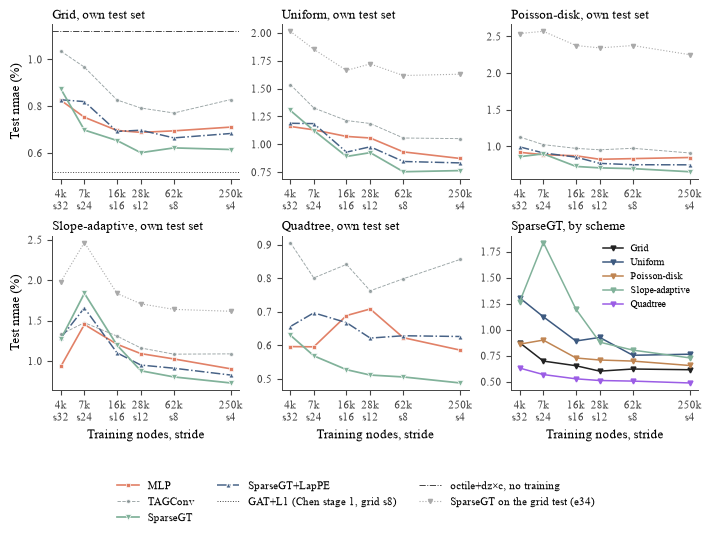

In [5]:
def plot_transfer(metric='nmae', ylabel='Test nmae (%)', fname='e34c_transfer_nmae', grid_ref=True):
    fig, axes = plt.subplots(2, 3, figsize=(7.0, 4.4), constrained_layout=True)
    ticks = sorted(res[res.scheme == 'grid'].drop_duplicates('stride')[['n_nodes', 'stride']].values.tolist())
    for ax, scheme in zip(axes.ravel(), SCHEMES):
        sub = matched[matched.scheme == scheme]
        for model in MODELS:
            g = sub[sub.model == model].sort_values('n_nodes')
            ax.plot(g.n_nodes, g[metric], marker=MARKERS[model], color=PALETTE[model], label=MODEL_NAMES[model],
                    markeredgecolor='white', markeredgewidth=0.5, **line_attrs(model))
        if grid_ref and scheme not in ('grid', 'quadtree'):   # quadtree's 20% on the grid test would flatten its panel
            g = res[(res.scheme == scheme) & (res.model == 'sgt2') & (res.test == 'grid')].sort_values('n_nodes')
            ax.plot(g.n_nodes, g[metric], marker='v', color='#aaa', lw=0.8, ms=3, ls=':', zorder=1,
                    label='SparseGT on the grid test (e34)')
        if scheme == 'grid':
            for name, (val, ls) in REFS_GRID['nmae' if metric == 'nmae' else 'acc2'].items():
                ax.axhline(val, color='#444', lw=0.7, ls=ls, label=name)
        ax.set_xscale('log'); ax.minorticks_off()
        ax.set_xticks([n for n, _ in ticks], [f'{n/1000:.0f}k\ns{s}' for n, s in ticks])
        ax.set_title(f'{SCHEME_TITLES[scheme]}, own test set')
        clean_axes(ax)
    ax = axes.ravel()[-1]
    for scheme in SCHEMES:
        g = matched[(matched.scheme == scheme) & (matched.model == 'sgt2')].sort_values('n_nodes')
        ax.plot(g.n_nodes, g[metric], marker='v', color=SCHEME_COLORS[scheme], lw=1.1, ms=3.5, label=SCHEME_TITLES[scheme])
    ax.set_xscale('log'); ax.minorticks_off()
    ax.set_xticks([n for n, _ in ticks], [f'{n/1000:.0f}k\ns{s}' for n, s in ticks])
    ax.set_title('SparseGT, by scheme'); ax.legend(frameon=False, fontsize=7); clean_axes(ax)
    for ax in axes[1, :]:
        ax.set_xlabel('Training nodes, stride')
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    seen = {}
    for ax in (axes[0, 0], axes[0, 1]):
        h, l = ax.get_legend_handles_labels()
        seen.update(dict(zip(l, h)))
    fig.legend(seen.values(), seen.keys(), loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.2))
    fig.savefig(FIGS / f'{fname}.pdf', bbox_inches='tight')
    plt.show()

plot_transfer()

Reading the curves:
- **Every scheme is close to the grid on its own test set.** At strides 4–12 the matched SparseGT error is 0.49–0.93% against 0.60–0.62% on the grid. The grey dotted lines are the e34 numbers on the grid test; the gap to them is the metric mismatch (0.9 points for uniform and slope-adaptive, 1.6 for Poisson-disk). The quadtree panel leaves out its grid-test line, 19.7–20.0%, which would flatten the panel.
- **The irregular schemes now have a transfer curve.** Error falls with training density down to stride 4, where the grid saturates at stride 12. The slope-adaptive bump at stride 24 is the sampling-seed outlier of e34 section 4.1, visible on every test set.
- **Quadtree is the easiest graph to fit** (0.49–0.63%); see the caveat at the top.

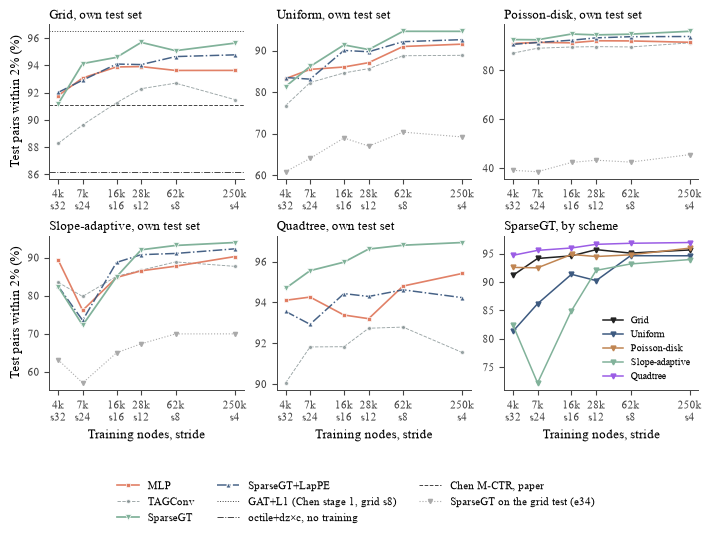

In [6]:
plot_transfer('acc2', 'Test pairs within 2% (%)', fname='e34c_transfer_acc2')

The train × test mismatch matrix: SparseGT trained on each scheme (rows), evaluated on each test set (columns).
Models trained on uniform and slope-adaptive graphs are interchangeable; Poisson-disk is its own family; quadtree
is 20% off every other metric and the other way round.

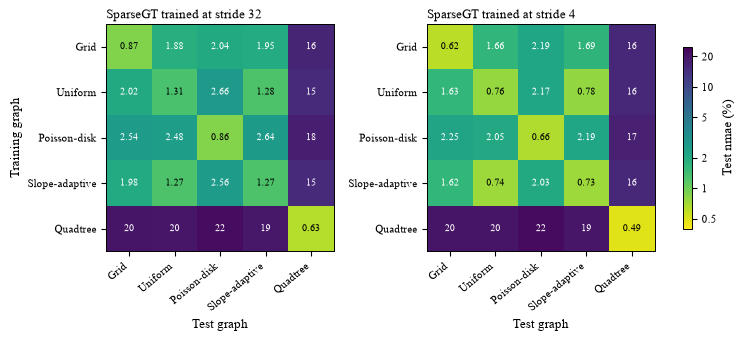

In [7]:
def plot_mismatch(strides=(32, 4), fname='e34c_mismatch_sgt2'):
    fig, axes = plt.subplots(1, len(strides), figsize=(3.3 * len(strides) + 0.8, 3.3), constrained_layout=True)
    for ax, stride in zip(axes, strides):
        M = res[(res.model == 'sgt2') & (res.stride == stride)].pivot_table(index='scheme', columns='test', values='nmae') \
            .reindex(index=SCHEMES, columns=SCHEMES)
        im = ax.imshow(np.log10(M.values), cmap='viridis_r', vmin=np.log10(0.4), vmax=np.log10(25))
        for i in range(5):
            for j in range(5):
                v = M.values[i, j]
                ax.text(j, i, f'{v:.2f}' if v < 10 else f'{v:.0f}', ha='center', va='center', fontsize=7,
                        color='white' if v > 1.5 else 'black')
        ax.set_xticks(range(5), [SCHEME_TITLES[s] for s in SCHEMES], rotation=40, ha='right')
        ax.set_yticks(range(5), [SCHEME_TITLES[s] for s in SCHEMES])
        ax.set_xlabel('Test graph'); ax.set_title(f'SparseGT trained at stride {stride}')
    axes[0].set_ylabel('Training graph')
    cb = fig.colorbar(im, ax=axes, shrink=0.8, label='Test nmae (%)')
    cb.set_ticks(np.log10([0.5, 1, 2, 5, 10, 20]), labels=['0.5', '1', '2', '5', '10', '20'])
    fig.savefig(FIGS / f'{fname}.pdf', bbox_inches='tight')
    plt.show()

plot_mismatch()

## 2. Sample paths on each scheme's stride-4 graph

The three pairs of `e34_transfer_suite.ipynb` section 2 (the grid pairs that bend most, 6–14 km), mapped to the nearest
node of each scheme's graph. The true path is Dijkstra on that graph. The model path is the greedy descent of the
SparseGT model trained on the same scheme at stride 4: from node $i$, step to the unvisited neighbour $j$ that
minimises $w_{ij} + \hat d(j, t)$. Embeddings are computed from `final_model.pt` and cached as float16.

In [8]:
import torch, yaml
sys.path.insert(0, str(REPO))
from spnn.models.factory import configure_embedding_module
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
MODEL_SPEC = {'mlp': ('MLP', 'configs/e31-mlp.yml'), 'tagconv': ('TAGConv', 'configs/e31-tagconv.yml'),
              'sgt2': ('SparseGT', 'configs/e32-sparse-gt-k2.yml'),
              'sgt2lap': ('SparseGT', 'configs/e35-sparse-gt-k2-lappe.yml')}
from spnn.graphs.spectral import laplacian_pe
def run_dir(scheme, stride, model):
    return (E35 if model == 'sgt2lap' else RUNS) / f'norway_{scheme}_s{stride:02d}_{model}'

TG = {}      # test graphs: node_features X, csr G, sources, kd-tree
for scheme, path in TESTS.items():
    d = np.load(path)
    X = d['node_features']; n = len(X)
    G = sp.csr_matrix((d['distances'], (d['edge_index'][0], d['edge_index'][1])), shape=(n, n))
    TG[scheme] = dict(X=X, G=G, ei=d['edge_index'], w=d['distances'], srcs=np.unique(d['srcs']), tree=cKDTree(X[:, :2]))
Xg = TG['grid']['X']; SIDE = 500
Z = Xg[:, 2].reshape(SIDE, SIDE)
EXTENT = [Xg[:, 0].min(), Xg[:, 0].max(), Xg[:, 1].min(), Xg[:, 1].max()]
GRID_SRCS = TG['grid']['srcs']
# the matched source of each grid source in each scheme graph (from the test-set sidecars)
SRC_MAP = {'grid': dict(zip(GRID_SRCS.tolist(), GRID_SRCS.tolist()))}
for scheme in SCHEMES[1:]:
    info = json.load(open(TESTDIR / f'norway_{scheme}_test-004.json'))
    SRC_MAP[scheme] = dict(zip(info['grid_sources'], info['sources']))

def nearest(scheme, node_on_grid):
    return int(TG[scheme]['tree'].query(Xg[node_on_grid, :2])[1])

def embeddings(scheme, stride, model, test):
    path = CACHE / f'emb_{scheme}_s{stride:02d}_{model}__{test}.npy'
    if path.exists():
        return np.load(path).astype(np.float32)
    layer_type, cfg_path = MODEL_SPEC[model]
    cfg = next(iter(yaml.safe_load(open(REPO / cfg_path)).values()))
    if layer_type == 'SparseGT':
        cfg['gnn'].setdefault('sparse_gt', {}).setdefault('embedding_mode', 'data')
    net = configure_embedding_module(cfg['gnn'], layer_type, edge_dim=1, new=True)
    weights = next(run_dir(scheme, stride, model).glob('models/**/final_model.pt'))
    net.load_state_dict(torch.load(weights, map_location='cpu'))
    net = net.to(DEVICE).eval()
    g = TG[test]
    x = torch.tensor(g['X'], dtype=torch.float, device=DEVICE)
    if getattr(net, 'embedding_mode', None) == 'lappe':   # the test graph's own eigenvectors, from the cache
        V, _ = laplacian_pe(len(g['X']), g['ei'], net.lappe_k, cache_dir=LAPPE)
        x = torch.cat([x, torch.from_numpy(V).to(DEVICE)], dim=1)
    with torch.no_grad():
        if layer_type == 'MLP':
            e = net(x)
        else:
            e = net(x, torch.tensor(g['ei'], dtype=torch.long, device=DEVICE),
                    edge_attr=torch.tensor(g['w'], dtype=torch.float, device=DEVICE).unsqueeze(-1))
    e = e.cpu().numpy()
    np.save(path, e.astype(np.float16))
    del net
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
    return e

def true_path(G, s, t):
    dist, pred = dijkstra(G, indices=s, return_predecessors=True)
    path = [t]
    while path[-1] != s:
        path.append(pred[path[-1]])
    return path[::-1], dist[t]

def greedy_path(G, E, s, t, max_steps=20000):
    h = np.abs(E - E[t]).sum(1)
    path, seen, i = [s], {s}, s
    while i != t and len(path) < max_steps:
        nb = G.indices[G.indptr[i]:G.indptr[i + 1]]
        wt = G.data[G.indptr[i]:G.indptr[i + 1]]
        ok = np.array([j not in seen for j in nb])
        if not ok.any():
            break
        nb, wt = nb[ok], wt[ok]
        i = int(nb[np.argmin(wt + h[nb])])
        path.append(i); seen.add(i)
    length = sum(G[a, b] for a, b in zip(path[:-1], path[1:]))
    return path, length, i == t, h[s]

PATH_PAIRS_GRID = [(247792, 185417), (137059, 232559), (158393, 228386)]   # e34 notebook section 2
PATH_STRIDE = 4
path_cache = CACHE / 'paths_matched_v1.json'
if path_cache.exists():
    PATHS = json.load(open(path_cache))
else:
    PATHS = {}
    for scheme in SCHEMES:
        E = embeddings(scheme, PATH_STRIDE, 'sgt2', scheme)
        for k, (sg, tg) in enumerate(PATH_PAIRS_GRID):
            s, t = nearest(scheme, sg), nearest(scheme, tg)
            tp, tl = true_path(TG[scheme]['G'], s, t)
            p, L, done, dhat = greedy_path(TG[scheme]['G'], E, s, t)
            PATHS[f'{k}/{scheme}'] = dict(src=s, tar=t, true=[int(v) for v in tp], true_km=float(tl),
                                          greedy=[int(v) for v in p], greedy_km=float(L), reached=bool(done), pred_km=float(dhat))
    json.dump(PATHS, open(path_cache, 'w'))

tab = []
for k in range(len(PATH_PAIRS_GRID)):
    for scheme in SCHEMES:
        q = PATHS[f'{k}/{scheme}']
        tab.append(dict(pair=k, scheme=scheme, true_km=round(q['true_km'], 3), predicted_km=round(q['pred_km'], 3),
                        pred_err_pct=round(100 * (q['pred_km'] - q['true_km']) / q['true_km'], 2),
                        greedy_km=round(q['greedy_km'], 3),
                        greedy_excess_pct=round(100 * (q['greedy_km'] - q['true_km']) / q['true_km'], 2),
                        reached=q['reached'], true_hops=len(q['true']) - 1))
pd.DataFrame(tab)

,pair,scheme,true_km,predicted_km,pred_err_pct,greedy_km,greedy_excess_pct,reached,true_hops
0,0,grid,7.903,7.601,-3.82,8.123,2.79,True,130
1,0,uniform,8.077,7.860,-2.69,8.919,10.42,True,141
2,0,poisson-disk,7.932,7.723,-2.63,8.241,3.90,True,149
3,0,slope-adaptive,8.065,7.836,-2.83,8.713,8.04,True,140
4,0,quadtree,10.271,10.150,-1.18,10.444,1.69,True,216
5,1,grid,8.450,8.363,-1.03,8.496,0.55,True,191
6,1,uniform,8.713,8.712,-0.02,9.099,4.43,True,149
7,1,poisson-disk,8.576,8.512,-0.74,8.703,1.48,True,160
8,1,slope-adaptive,8.712,8.696,-0.19,9.271,6.41,True,145
9,1,quadtree,8.473,8.544,0.84,8.473,0.00,True,190


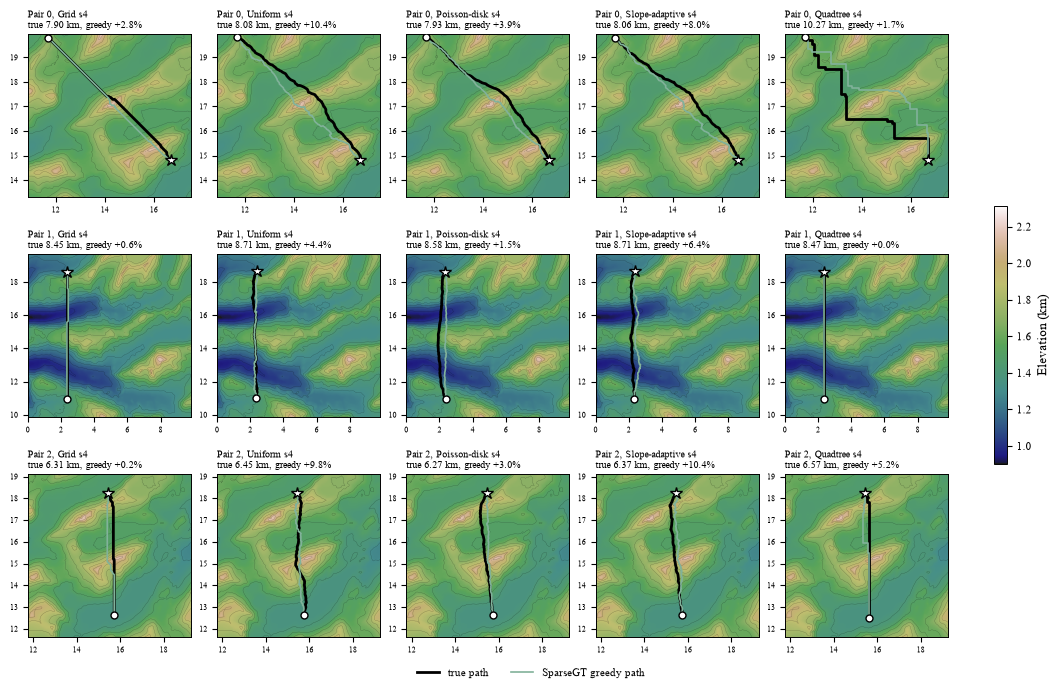

In [9]:
def plot_paths(fname='e34c_paths_matched'):
    fig, axes = plt.subplots(len(PATH_PAIRS_GRID), len(SCHEMES), figsize=(10.5, 6.6), constrained_layout=True)
    for k in range(len(PATH_PAIRS_GRID)):
        pts = np.concatenate([TG[s]['X'][np.array(PATHS[f'{k}/{s}']['true'] + PATHS[f'{k}/{s}']['greedy'])] for s in SCHEMES])
        x0, x1, y0, y1 = pts[:, 0].min(), pts[:, 0].max(), pts[:, 1].min(), pts[:, 1].max()
        half = min(0.6 * max(x1 - x0, y1 - y0) + 0.3, (EXTENT[1] - EXTENT[0]) / 2)
        cx = np.clip((x0 + x1) / 2, EXTENT[0] + half, EXTENT[1] - half)
        cy = np.clip((y0 + y1) / 2, EXTENT[2] + half, EXTENT[3] - half)
        for c, scheme in enumerate(SCHEMES):
            ax = axes[k, c]; q = PATHS[f'{k}/{scheme}']; X = TG[scheme]['X']
            im = ax.imshow(Z, origin='lower', extent=EXTENT, cmap='gist_earth', alpha=0.9)
            ax.contour(Z, levels=15, origin='lower', extent=EXTENT, colors='k', linewidths=0.2, alpha=0.4)
            tp, gp = np.array(q['true']), np.array(q['greedy'])
            ax.plot(X[tp, 0], X[tp, 1], color='k', lw=2.0, label='true path', zorder=4)
            ax.plot(X[gp, 0], X[gp, 1], color=PALETTE['sgt2'], lw=1.2, zorder=5, label='SparseGT greedy path')
            ax.plot(*X[q['src'], :2], 'o', color='white', mec='k', ms=5, zorder=6)
            ax.plot(*X[q['tar'], :2], '*', color='white', mec='k', ms=9, zorder=6)
            ax.set_xlim(cx - half, cx + half); ax.set_ylim(cy - half, cy + half); ax.set_aspect('equal')
            ax.set_title(f"Pair {k}, {SCHEME_TITLES[scheme]} s4\ntrue {q['true_km']:.2f} km, greedy {100 * (q['greedy_km'] / q['true_km'] - 1):+.1f}%",
                         fontsize=7)
            ax.tick_params(labelsize=6)
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.04))
    fig.colorbar(im, ax=axes, shrink=0.4, label='Elevation (km)')
    fig.savefig(FIGS / f'{fname}.pdf', bbox_inches='tight')
    plt.show()

plot_paths()

## 3. Error heatmaps on the matched tests

The hard source of the e34 notebook (grid node 239655) and its matched node in each scheme graph. Each panel shows the
signed relative error $(\hat d - d)/d$ of a model for every node of its own test graph as target, rasterised to the
500 × 500 grid by nearest neighbour. Red: the model overestimates; blue: it underestimates.

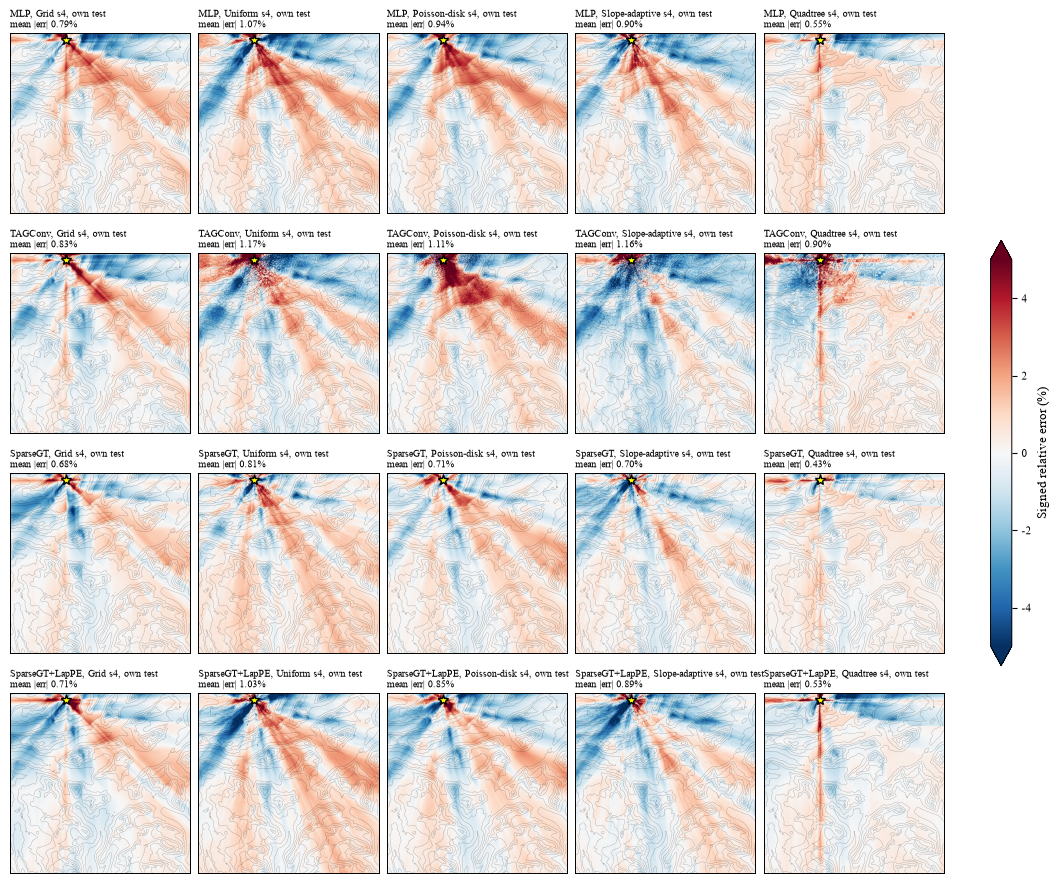

In [10]:
HARD_SRC = 239655
xi = np.linspace(EXTENT[0], EXTENT[1], SIDE); yi = np.linspace(EXTENT[2], EXTENT[3], SIDE)
XI, YI = np.meshgrid(xi, yi)

def rel_error_map(scheme, stride, model, test, src_grid=HARD_SRC):
    # Signed relative error (fraction) for one source, as a 500 x 500 image in the grid frame.
    path = CACHE / f'heat_{scheme}_s{stride:02d}_{model}__{test}_src{src_grid}.npy'
    if path.exists():
        return np.load(path)
    d = np.load(TESTS[test]); src = SRC_MAP[test][src_grid]
    sel = d['srcs'] == src
    pred = np.load(E34C / 'preds' / f'norway_{scheme}_s{stride:02d}_{model}__{test}.npy').astype(np.float32)[sel]
    true, tars = d['lengths'][sel], d['tars'][sel]
    rel = np.where(true > 0, (pred - true) / np.maximum(true, 1e-9), np.nan).astype(np.float32)
    if test == 'grid':
        m = np.full(SIDE * SIDE, np.nan, dtype=np.float32); m[tars] = rel; m = m.reshape(SIDE, SIDE)
    else:
        P = TG[test]['X'][tars]
        m = griddata(P[:, :2], rel, (XI, YI), method='nearest').astype(np.float32)
    np.save(path, m)
    return m

def plot_matched_heatmaps(stride=4, vmax=5.0, fname=None):
    models = [m for m in MODELS if all((E34C / 'preds' / f'norway_{s}_s{stride:02d}_{m}__{s}.npy').exists() for s in SCHEMES)]
    fig, axes = plt.subplots(len(models), len(SCHEMES), figsize=(10.5, 2.2 * len(models)), constrained_layout=True)
    for r, model in enumerate(models):
        for c, scheme in enumerate(SCHEMES):
            ax = axes[r, c]
            m = 100 * rel_error_map(scheme, stride, model, scheme)
            im = ax.imshow(m, origin='lower', extent=EXTENT, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
            ax.contour(Z, levels=10, origin='lower', extent=EXTENT, colors='k', linewidths=0.2, alpha=0.4)
            ax.plot(*Xg[HARD_SRC, :2], '*', color='yellow', mec='k', ms=8)
            ax.set_title(f'{MODEL_NAMES[model]}, {SCHEME_TITLES[scheme]} s{stride}, own test\nmean |err| {np.nanmean(np.abs(m)):.2f}%', fontsize=7)
            ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=axes, shrink=0.5, label='Signed relative error (%)', extend='both')
    if fname:
        fig.savefig(FIGS / f'{fname}.pdf', bbox_inches='tight')
    plt.show()

plot_matched_heatmaps(4, fname='e34c_heatmaps_matched_s04')

The same for models trained at stride 32 (4k nodes), the coarsest training graphs:

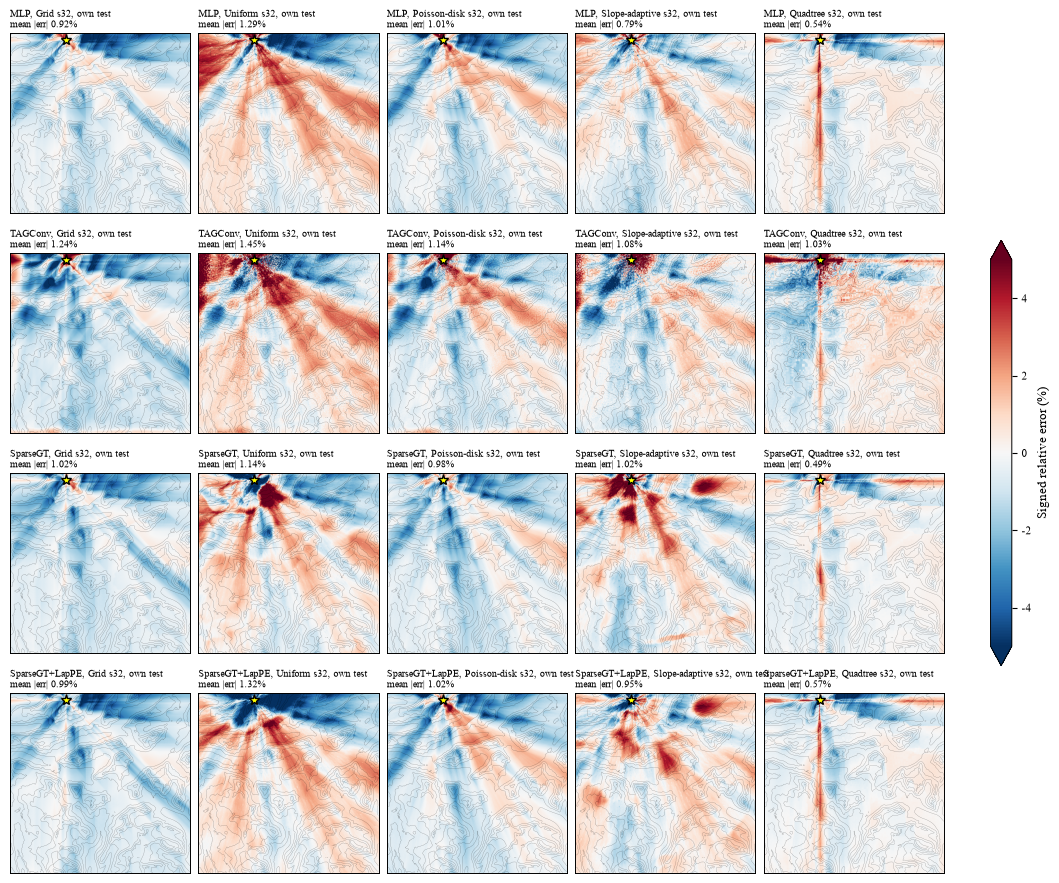

In [11]:
plot_matched_heatmaps(32, fname='e34c_heatmaps_matched_s32')

### 3.1 The mismatch itself: grid and uniform models on both test sets

SparseGT trained on the grid and on the uniform graph, each evaluated on the grid test and on the uniform test. The rays
along 0°, 45° and 90° appear only off the model's own graph family, with opposite sign in the two directions: the
uniform model overestimates along the grid axes on the grid test, the grid model underestimates there on the uniform test.

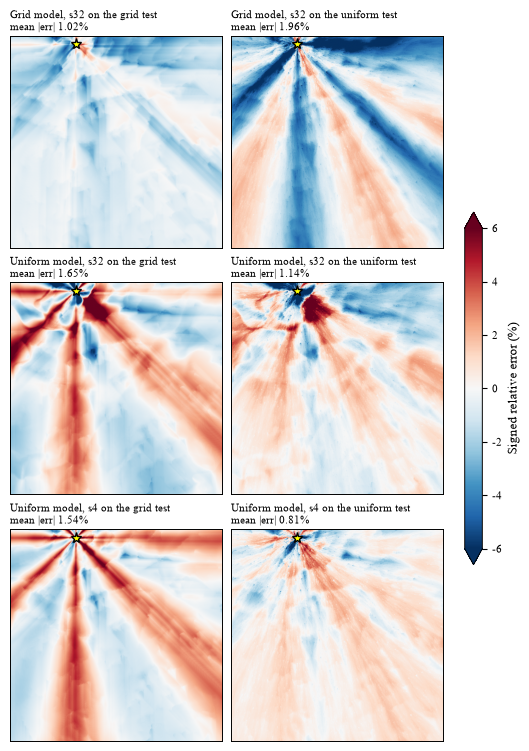

In [12]:
def plot_mismatch_heatmaps(vmax=6.0, fname='e34c_heatmap_grid_vs_uniform_test'):
    runs = [('grid', 32, 'Grid model, s32'), ('uniform', 32, 'Uniform model, s32'), ('uniform', 4, 'Uniform model, s4')]
    fig, axes = plt.subplots(len(runs), 2, figsize=(5.2, 7.4), constrained_layout=True)
    for i, (scheme, stride, lab) in enumerate(runs):
        for j, test in enumerate(['grid', 'uniform']):
            ax = axes[i, j]
            m = 100 * rel_error_map(scheme, stride, 'sgt2', test)
            im = ax.imshow(m, origin='lower', extent=EXTENT, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
            ax.plot(*Xg[HARD_SRC, :2], '*', color='yellow', mec='k', ms=8)
            ax.set_title(f'{lab} on the {test} test\nmean |err| {np.nanmean(np.abs(m)):.2f}%', fontsize=8)
            ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=axes, shrink=0.5, label='Signed relative error (%)', extend='both')
    fig.savefig(FIGS / f'{fname}.pdf', bbox_inches='tight')
    plt.show()

plot_mismatch_heatmaps()